# Simulation of the Convolution of Neutron spectrum and Chopper opening function
Create increasingly difficult neutron spectra  
Create increasingly difficult chopper functions  
Convolute the functions  
Compare the outputs of the convoluted functions to the output of approximations

In [65]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import math
import scipy as scp

#plt.style.use('stylesheet.mplstyle')

In [66]:
class SimUCNs:
    def __init__(self, name, num_v=10):
        self.name = name
        self.num_v = num_v
        self.data = np.zeros(num_v)

    def set_velocity(self, v_mps, N=100):
        if v_mps < 0 or v_mps >= self.num_v:
            raise ValueError("Velocity index out of bounds")
        self.data[v_mps]=N

    def plot(self):
        plt.clf()
        plt.scatter(range(self.num_v), self.data, label=self.name, color='#9DD9D2')
        plt.xlabel("v [m/s]")
        plt.ylabel("N [counts]")
        plt.title("Simulated incoming UCNs")
        plt.legend()
        plt.grid(True)
        plt.show()

In [67]:
class Chopper:
    def __init__(self, name, num_chop=10):
        self.name = name
        self.num_chop = num_chop
        self.data = np.zeros(num_chop)

    def set_open_at(self, t_ms, fraction=1):
        if t_ms < 0 or t_ms >= self.num_chop:
            raise ValueError("Time index out of bounds")
        self.data[t_ms]=fraction

    def plot(self):
        plt.clf()
        plt.scatter(range(self.num_chop), self.data, label=self.name)
        plt.xlabel("t [ms]")
        plt.ylabel("Open")
        plt.title("Chopper opening function")
        plt.legend()
        plt.grid(True)
        plt.show()

In [128]:
class Detector:
    def __init__(
            self,
            num_bins = 4000,
            t_max_ms = 400,
            s_mm = 639,
            do_cycle = False):
        self.num_bins = num_bins
        self.t_max_ms = t_max_ms
        self.s_mm = s_mm
        self.do_cycle = do_cycle
        self.data = np.zeros(num_bins)
        self.bins_per_ms = num_bins/t_max_ms

    def plot(self):
        plt.clf()
        plt.scatter(range(self.num_bins), self.data, label="TOF detector data", color='#392F5A')
        plt.xlabel("# bin")
        plt.ylabel("counts")
        plt.title("Measured UCNs")
        plt.legend()
        plt.grid(True)
        plt.show()

    def measure(self, neutrons, chopper):
        if not isinstance(neutrons, SimUCNs):
            raise TypeError("Argument 'neutrons' must be of type 'SimUCNs'")
        if not isinstance(chopper, Chopper):
            raise TypeError("Argument 'chopper' must be of type 'Chopper'")

        for tstart_ms in range(len(chopper.data)):
            for v in range(len(neutrons.data)):
                if np.abs(v) > 0.01:
                    t_ms =  self.s_mm/v
                    t_total_ms = tstart_ms + t_ms
                    bin = math.floor(self.bins_per_ms*t_total_ms)
                    if self.do_cycle == True:
                        self.data[bin % self.num_bins]+=chopper.data[tstart_ms]*neutrons.data[v]
                    else:
                        if bin < self.num_bins:
                            self.data[bin]+=chopper.data[tstart_ms]*neutrons.data[v]


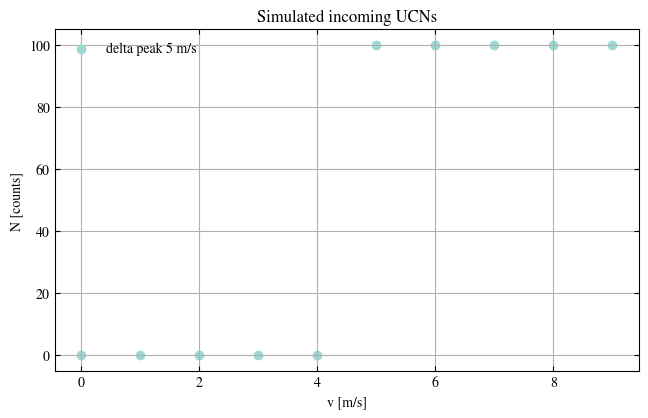

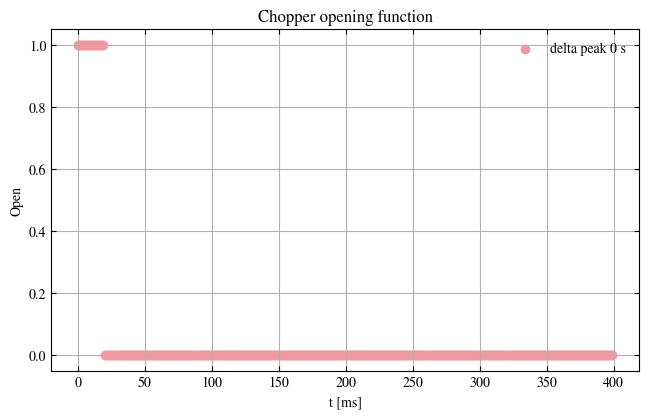

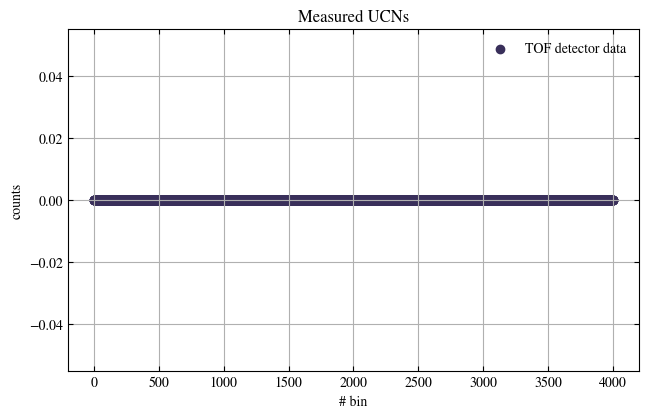

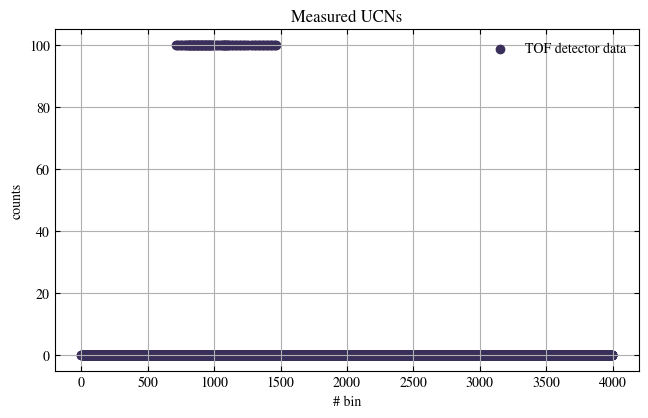

0.0


In [130]:
# v delta peak at v = 5 m/s
v_two = SimUCNs("delta peak 5 m/s", num_v=10)
v_two.set_velocity(5) # peak at 5 m/s
v_two.set_velocity(6)
v_two.set_velocity(7)
v_two.set_velocity(8)
v_two.set_velocity(9)
v_two.plot()

# chopper delta peak at t = 0 s
chop_two = Chopper("delta peak 0 s", num_chop=400)
for i in range(20):
    chop_two.set_open_at(i)
chop_two.plot()

# detector
detector1 = Detector(num_bins=4000, s_mm=639, do_cycle=False)
detector1.plot()
detector1.measure(v_two, chop_two)
detector1.plot()
print(detector1.data[127])
